In [40]:
#使用pytorch实现mlp模型，使用MNIST数据集训练
from collections import defaultdict

import dnnlpy
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
import torch.utils.data as utils
import torchvision.datasets as datasets
import torchvision.transforms.v2 as v2
from torch import Tensor

In [41]:
#创建MLP神经网络
class MLP(nn.Module):
    #定义名为MLP的类，继承父类nn.Module（pytorch的神经网络基类）
    def __init__( #定义MLP的初始化函数，用于初始化对象self
            self,#self指的是MLP的对象，model=MLP()，model就是self
            input_dim:int=784,
            hidden_dim:int=256,
            num_classes:int=10,
    ):
        super().__init__()
            #调用父类nn.Module的初始化函数，用于初始化PyTorch管理网络层和参数所需的内部机制
        self.net=nn.Sequential(
            #用torch的容器函数.Sequential()给self对象按顺序组建神经网络层，并赋值到属性net中
            nn.Flatten(),
            nn.Linear(input_dim,hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim,num_classes)
        )

    #forward
    def forward(self,x:Tensor)->Tensor:
        #定义forward成员函数，传入参数为x张量，返回值类型为张量
        return self.net(x)

In [42]:
#准备MNIST数据集
#数据存放路径root
root = dnnlpy.get_data_root()

#transform将mnist数据集转换成torch的tensor形式：(通道数, 高, 宽)，即(1，28，28)。并且把像素值缩放到[0,1]
transform = v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])

#训练&测试数据
train_ds = datasets.MNIST(root, train=True, download=True, transform=transform)
test_ds = datasets.MNIST(root, train=False, download=True, transform=transform)

#DataLoader：Torch的DataLoader 会自动帮我们完成打乱数据、分batch和迭代（迭代就是总样本数1280，每次取128个，迭代10次取完）
train_dl = utils.DataLoader(train_ds, batch_size=128, shuffle=True)
test_dl = utils.DataLoader(test_ds, batch_size=256, shuffle=False)

In [43]:
#定义训练设备device
device=dnnlpy.get_default_device()
print('Using device:',device)

Using device: mps


In [44]:
#创建mlp模型、损失函数、优化器
model=MLP(input_dim=784,hidden_dim=256,num_classes=10).to(device)
loss_fn=nn.CrossEntropyLoss()
optimizer=optim.SGD(model.parameters(),lr=0.1)
history=defaultdict(list)

In [45]:
#训练
num_epochs=10
for epoch in range(1,num_epochs+1):
    #模型进入训练模式，开启dropout和BatchNorm
    model.train()
    train_loss=0.0
    correct_samples=0

    #zero_grad -> forward -> loss -> backward -> step
    #从train_dl中每次迭代batch_size大小的数据来训练，直到整个train_ds被迭代完，都被拿去训练
    for X,y in train_dl:
        X=X.to(device) #将数据读取到gpu上运行
        y=y.to(device)

        logits=model(X)
        loss=loss_fn(logits,y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        train_loss+=loss.item()
        correct_samples+=(logits.argmax(dim=1)==y).sum().item()

    #记录本次epoch训练过程的每个batch的平均损失、平均准确率
    avg_train_loss=train_loss/len(train_dl)
    avg_train_acc=correct_samples/len(train_ds)
    history['loss'].append(avg_train_loss)
    history['acc'].append(avg_train_acc)

    #模型进入测试模式
    model.eval()
    test_loss=0.0
    correct_samples=0

    for X,y in test_dl:
        X=X.to(device)
        y=y.to(device)

        with torch.inference_mode(): #这里代码让torch不记录反向传播的计算图，以节省显存
            logits=model(X)
            loss=loss_fn(logits,y)

        test_loss+=loss.item()
        correct_samples+=(logits.argmax(dim=1)==y).sum().item()

    avg_test_loss=test_loss/len(test_dl)
    avg_test_acc=correct_samples/len(test_ds)
    history['test_loss'].append(avg_test_loss)
    history['test_acc'].append(avg_test_acc)

    #打印每个epoch的训练数据
    n = len(str(num_epochs))
    print(
        f'Epoch [{epoch:{n}d}/{num_epochs:{n}d}] '
        f'| loss: {avg_train_loss:.4f} '
        f'| acc: {avg_train_acc:.4f} '
        f'| test_loss: {avg_test_loss:.4f} '
        f'| test_acc: {avg_test_acc:.4f}'
    )

Epoch [ 1/10] | loss: 0.5722 | acc: 0.8564 | test_loss: 0.3087 | test_acc: 0.9130
Epoch [ 2/10] | loss: 0.2895 | acc: 0.9179 | test_loss: 0.2405 | test_acc: 0.9317
Epoch [ 3/10] | loss: 0.2355 | acc: 0.9326 | test_loss: 0.2025 | test_acc: 0.9409
Epoch [ 4/10] | loss: 0.1981 | acc: 0.9445 | test_loss: 0.1756 | test_acc: 0.9472
Epoch [ 5/10] | loss: 0.1699 | acc: 0.9518 | test_loss: 0.1556 | test_acc: 0.9538
Epoch [ 6/10] | loss: 0.1492 | acc: 0.9580 | test_loss: 0.1402 | test_acc: 0.9588
Epoch [ 7/10] | loss: 0.1323 | acc: 0.9628 | test_loss: 0.1270 | test_acc: 0.9616
Epoch [ 8/10] | loss: 0.1185 | acc: 0.9671 | test_loss: 0.1175 | test_acc: 0.9656
Epoch [ 9/10] | loss: 0.1072 | acc: 0.9701 | test_loss: 0.1060 | test_acc: 0.9672
Epoch [10/10] | loss: 0.0980 | acc: 0.9732 | test_loss: 0.1019 | test_acc: 0.9692


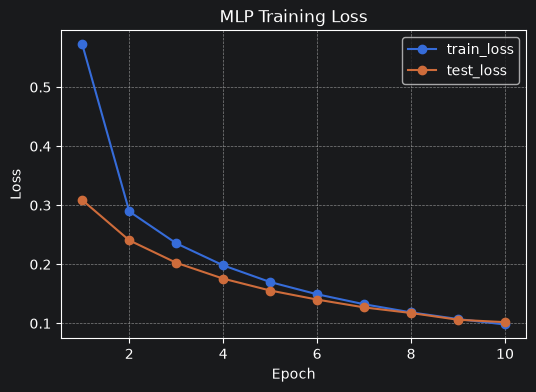

In [46]:
#可视化训练过程的损失值loss
fig = plt.figure(1, figsize=(6, 4))
ax = fig.add_subplot(1, 1, 1)
xticks = torch.arange(1, num_epochs + 1)
ax.plot(xticks, history['loss'], marker='o')
ax.plot(xticks, history['test_loss'], marker='o')
ax.grid(linestyle='--', alpha=0.7)
ax.set_xlabel('Epoch')
ax.set_ylabel('Loss')
ax.legend(['train_loss', 'test_loss'])
ax.set_title('MLP Training Loss')
plt.show()

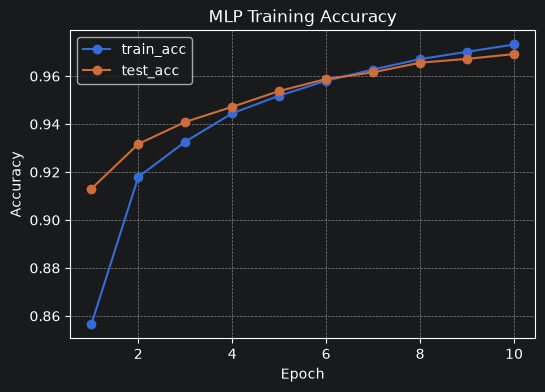

In [47]:
#可视化训练过程的准确度acc
fig = plt.figure(2, figsize=(6, 4))
ax = fig.add_subplot(1, 1, 1)
xticks = torch.arange(1, num_epochs + 1)
ax.plot(xticks, history['acc'], marker='o')
ax.plot(xticks, history['test_acc'], marker='o')
ax.grid(linestyle='--', alpha=0.7)
ax.set_xlabel('Epoch')
ax.set_ylabel('Accuracy')
ax.legend(['train_acc', 'test_acc'])
ax.set_title('MLP Training Accuracy')
plt.show()

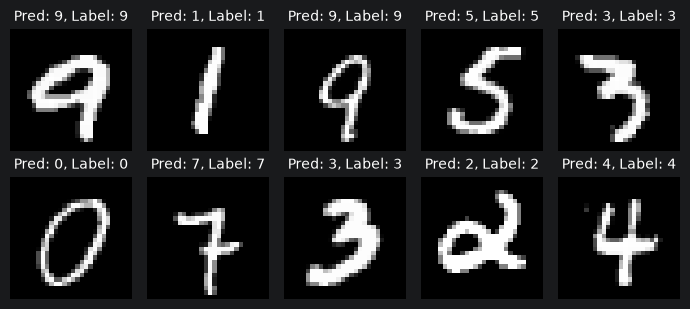

In [48]:
#随机选10张图检测模型的能力
indices = torch.randperm(len(test_ds))[:10]
x_samples = torch.stack([test_ds[i][0] for i in indices])
y_samples = torch.tensor([test_ds[i][1] for i in indices])

model.cpu().eval()
with torch.inference_mode():
    logits = model(x_samples)
    y_preds = logits.argmax(dim=1)

fig = plt.figure(3, figsize=(7, 3.2))
axes = fig.subplots(2, 5)
for i, ax in enumerate(axes.ravel()):
    ax.imshow(x_samples[i].reshape(28, 28), cmap='gray')
    ax.axis('off')
    ax.set_title(f'Pred: {y_preds[i]}, Label: {y_samples[i]}', fontsize=10)
fig.tight_layout()
plt.show()